# Telecom Customer Churn Analysis

**Business question:** Which customers are leaving, how much recurring revenue (MRR) are we losing, and where should retention effort go first?

**Data:** IBM Telco customer churn dataset (7,043 customers, snapshot date 30-Sep-2019).

**Important:** a few columns were *simulated* in the data-build step because they do not exist in the public dataset: `subscription_type`, `complaint_count`, `complaint_date`, `escalations`, `csat_score`, `dob`, `cancellation_date`, `customer_name`. They are not used to draw conclusions in this notebook (complaint KPIs are shown and labelled "simulated").

**Flow:** setup, load, data-quality checks, cleaning, KPI scorecard, segment analysis, drivers, recommendations.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SNAPSHOT = pd.Timestamp("2019-09-30")      # date the dataset was taken (never use today())
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.options.display.float_format = "{:,.2f}".format

## 2. Load data
`churn_data.csv` is the file built from the IBM dataset. We also pull a few **real** columns back from the original Excel file (contract, tenure, internet service, payment method, tech support, senior citizen, dependents) because they carry genuine signal.

In [2]:
DATE_COLS = ["subscription_start_date", "renewal_date", "cancellation_date", "complaint_date", "dob"]
df = pd.read_csv("churn_data.csv", parse_dates=DATE_COLS)

RAW_COLS = {
    "CustomerID": "customerid",
    "Tenure Months": "tenure_months",
    "Contract": "contract",
    "Internet Service": "internet_service",
    "Payment Method": "payment_method",
    "Tech Support": "tech_support",
    "Senior Citizen": "senior_citizen",
    "Dependents": "dependents",
}
raw = pd.read_csv("telco_raw_columns.csv", usecols=list(RAW_COLS)).rename(columns=RAW_COLS)
df = df.merge(raw, on="customerid", how="left", validate="1:1")
print("Shape after merge:", df.shape)
df.head()

Shape after merge: (7043, 28)


,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,escalations,csat_score,complaint_count,tenure_months,contract,internet_service,payment_method,tech_support,senior_citizen,dependents
0,3668-QPYBK,2019-07-31,Paid,2019-08-30,Standard,Monthly,2019-09-08,Competitor made better offer,53.85,3239,...,NaN,NaN,0,2,Month-to-month,DSL,Mailed check,No,No,No
1,9237-HQITU,2019-07-31,Paid,2019-08-30,Standard,Monthly,2019-08-04,Moved,70.70,2701,...,N,35.00,2,2,Month-to-month,Fiber optic,Electronic check,No,No,No
2,9305-CDSKC,2019-02-01,Paid,2019-03-03,Premium,Monthly,2019-07-27,Moved,99.65,5372,...,NaN,NaN,0,8,Month-to-month,Fiber optic,Electronic check,No,No,No
3,7892-POOKP,2017-06-11,Paid,2017-09-09,Premium,Monthly,2019-08-08,Moved,104.80,5003,...,N,30.00,1,28,Month-to-month,Fiber optic,Electronic check,Yes,No,No
4,0280-XJGEX,2015-09-20,Referral,2016-02-17,Premium,Monthly,2019-09-16,Competitor had better devices,103.70,5340,...,N,25.00,4,49,Month-to-month,Fiber optic,Bank transfer (automatic),No,No,No


## 3. Data quality checks
Before analysing anything: nulls, duplicates, outliers and whether the missing values make sense.

In [3]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "nulls": df.isna().sum(),
    "null_%": df.isna().mean() * 100,
    "unique": df.nunique(),
})
display(quality.sort_values("nulls", ascending=False))

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerid"].duplicated().sum())

# Nulls in cancellation fields are expected ONLY for customers who did not churn
active = df["churn_flag"] == 0
print("cancellation_date empty only for active customers:", df.loc[active, "cancellation_date"].isna().all() and df.loc[~active, "cancellation_date"].notna().all())
print("cancellation_reason empty only for active customers:", df.loc[active, "cancellation_reason"].isna().all() and df.loc[~active, "cancellation_reason"].notna().all())

display(df[["monthly_charges", "tenure_months", "cltv"]].describe())

,dtype,nulls,null_%,unique
cancellation_date,datetime64[ns],5174,73.46,90
cancellation_reason,object,5174,73.46,20
csat_score,float64,3450,48.98,19
escalations,object,3450,48.98,2
complaint_date,datetime64[ns],3450,48.98,119
customerid,object,0,0.00,7043
gender,object,0,0.00,2
senior_citizen,object,0,0.00,2
tech_support,object,0,0.00,3
payment_method,object,0,0.00,4


Duplicate rows: 0
Duplicate customer IDs: 0
cancellation_date empty only for active customers: True
cancellation_reason empty only for active customers: True


,monthly_charges,tenure_months,cltv
count,"7,043.00","7,043.00","7,043.00"
mean,64.76,32.37,"4,400.30"
std,30.09,24.56,"1,183.06"
min,18.25,0.00,"2,003.00"
25%,35.50,9.00,"3,469.00"
50%,70.35,29.00,"4,527.00"
75%,89.85,55.00,"5,380.50"
max,118.75,72.00,"6,500.00"


**What to note here:** these nulls are *structural* (no cancellation if the customer never cancelled), so we keep them as missing rather than filling them. Write one sentence on each null column in your own words.

## 4. Cleaning & feature engineering

In [4]:
# Drop columns with no information (single value or placeholder text)
df = df.drop(columns=["customer_name", "country", "state"])

# Ordered categories so groupbys and charts sort in a sensible order
df["plan_type"] = pd.Categorical(df["plan_type"], ["Basic", "Standard", "Premium"], ordered=True)
df["contract"] = pd.Categorical(df["contract"], ["Month-to-month", "One year", "Two year"], ordered=True)

# Tenure buckets (real tenure in months)
df["tenure_bucket"] = pd.cut(df["tenure_months"], bins=[-1, 6, 12, 24, 48, np.inf],
                             labels=["0-6", "7-12", "13-24", "25-48", "49+"])

# Risk tier from the churn score. The score is a model output, so use it to RANK active customers,
# not to explain why people churn.
df["churn_risk"] = pd.cut(df["churn_score"], bins=[-1, 49, 69, 100], labels=["low", "med", "high"])

# Revenue and label helpers
df["mrr_lost"] = df["monthly_charges"] * df["churn_flag"]
df["status"] = df["churn_flag"].map({0: "Retained", 1: "Churned"})

# Complaint flags (simulated columns). Keep NaN for customers with no complaint instead of forcing 0.
df["complaint_flag"] = (df["complaint_count"] > 0).astype(int)
df["escalated"] = df["escalations"].map({"Y": 1, "N": 0})

df[["contract", "tenure_bucket", "churn_risk", "mrr_lost"]].head()

,contract,tenure_bucket,churn_risk,mrr_lost
0,Month-to-month,0-6,high,53.85
1,Month-to-month,0-6,med,70.70
2,Month-to-month,7-12,high,99.65
3,Month-to-month,25-48,high,104.80
4,Month-to-month,49+,high,103.70


## 5. KPI scorecard
All KPIs in one table. Fixes vs the first version: tenure uses real tenure (not `today()`), "revenue at risk" now means *active* high-risk customers, and escalation rate is measured among customers who complained.

In [5]:
total_customers = len(df)
churn_rate = df["churn_flag"].mean() * 100
total_mrr = df["monthly_charges"].sum()
lost_mrr = df["mrr_lost"].sum()
at_risk_mrr = df.loc[(df["churn_flag"] == 0) & (df["churn_risk"] == "high"), "monthly_charges"].sum()
avg_tenure = df.groupby("status")["tenure_months"].mean()

kpis = [
    ("Customers", f"{total_customers:,}"),
    ("Churn rate", f"{churn_rate:.1f}%"),
    ("Retention rate", f"{100 - churn_rate:.1f}%"),
    ("ARPU (monthly)", f"${df['monthly_charges'].mean():,.2f}"),
    ("Total MRR", f"${total_mrr:,.0f}"),
    ("MRR lost to churn", f"${lost_mrr:,.0f}  ({lost_mrr / total_mrr:.1%} of MRR)"),
    ("Annualised revenue lost", f"${lost_mrr * 12:,.0f}"),
    ("MRR at risk (active, high risk)", f"${at_risk_mrr:,.0f}"),
    ("CLTV lost", f"${df.loc[df['churn_flag'] == 1, 'cltv'].sum():,.0f}"),
    ("Avg tenure, churned / retained (months)", f"{avg_tenure['Churned']:.1f} / {avg_tenure['Retained']:.1f}"),
    ("Complaint rate (simulated)", f"{df['complaint_flag'].mean():.1%}"),
    ("Escalation rate among complainers (simulated)", f"{df['escalated'].mean():.1%}"),
]
display(pd.DataFrame(kpis, columns=["KPI", "Value"]).set_index("KPI"))

,Value
KPI,
Customers,"7,043"
Churn rate,26.5%
Retention rate,73.5%
ARPU (monthly),$64.76
Total MRR,"$456,117"
MRR lost to churn,"$139,131 (30.5% of MRR)"
Annualised revenue lost,"$1,669,570"
"MRR at risk (active, high risk)","$57,568"
CLTV lost,"$7,755,256"


## 6. Where is churn concentrated?
Contract type, price band and tenure. The dashed line is overall churn.

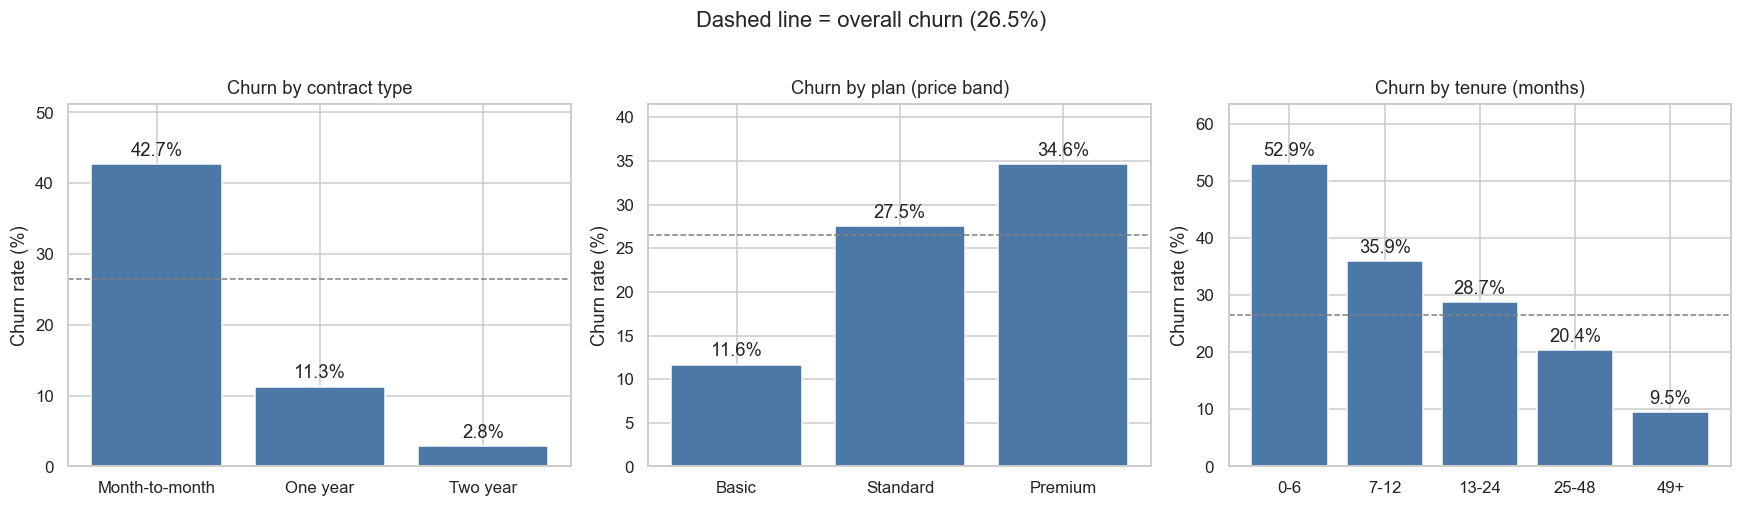

,customers,churn_rate,mrr,mrr_lost
contract,,,,
Month-to-month,3875,42.71,"257,294.15","120,847.10"
One year,1473,11.27,"95,816.60","14,118.45"
Two year,1695,2.83,"103,005.85","4,165.30"


In [6]:
def churn_by(col):
    """Customers, churn rate (%), MRR and MRR lost for each value of `col`."""
    out = df.groupby(col, observed=True).agg(
        customers=("customerid", "count"),
        churn_rate=("churn_flag", "mean"),
        mrr=("monthly_charges", "sum"),
        mrr_lost=("mrr_lost", "sum"),
    )
    out["churn_rate"] *= 100
    return out

def churn_bar(ax, col, title):
    t = churn_by(col)
    bars = ax.bar(t.index.astype(str), t["churn_rate"], color="#4C78A8")
    ax.bar_label(bars, labels=[f"{v:.1f}%" for v in t["churn_rate"]], padding=3)
    ax.axhline(churn_rate, ls="--", color="grey", lw=1)
    ax.set_title(title)
    ax.set_ylabel("Churn rate (%)")
    ax.set_ylim(0, t["churn_rate"].max() * 1.2)
    return t

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
t_contract = churn_bar(axes[0], "contract", "Churn by contract type")
t_plan = churn_bar(axes[1], "plan_type", "Churn by plan (price band)")
t_tenure = churn_bar(axes[2], "tenure_bucket", "Churn by tenure (months)")
fig.suptitle(f"Dashed line = overall churn ({churn_rate:.1f}%)", y=1.02)
plt.tight_layout()
plt.show()

display(t_contract)

**Write your insight here** (replace the title above with it too), for example: "Month-to-month customers churn at X% vs Y% on two-year contracts, and most churn happens in the first N months."

## 7. Why do customers leave?
Cancellation reasons ranked by MRR lost (Pareto chart). This is real data and the most actionable chart in the notebook.

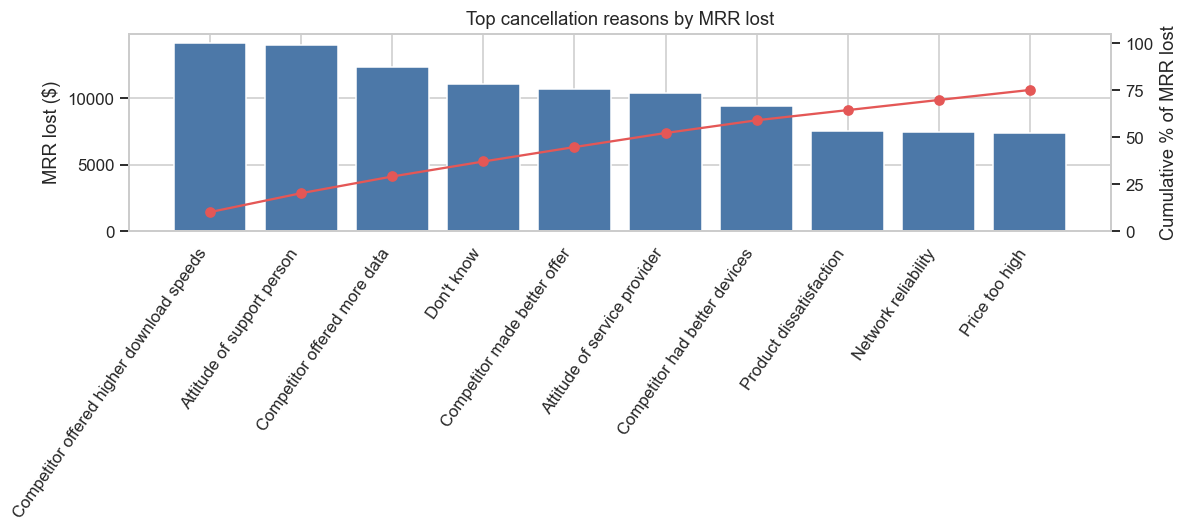

,customers,mrr_lost,cum_pct
cancellation_reason,,,
Competitor offered higher download speeds,189,"14,144.60",10.17
Attitude of support person,192,"13,980.85",20.22
Competitor offered more data,162,"12,351.75",29.09
Don't know,154,"11,099.05",37.07
Competitor made better offer,140,"10,672.10",44.74
Attitude of service provider,135,"10,399.30",52.22
Competitor had better devices,130,"9,432.35",58.99
Product dissatisfaction,102,"7,528.65",64.41
Network reliability,103,"7,497.55",69.79


In [7]:
reasons = (df[df["churn_flag"] == 1]
           .groupby("cancellation_reason")
           .agg(customers=("customerid", "count"), mrr_lost=("mrr_lost", "sum"))
           .sort_values("mrr_lost", ascending=False))
reasons["cum_pct"] = reasons["mrr_lost"].cumsum() / reasons["mrr_lost"].sum() * 100
top = reasons.head(10)

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(top.index, top["mrr_lost"], color="#4C78A8")
ax.set_ylabel("MRR lost ($)")
ax.set_title("Top cancellation reasons by MRR lost")
plt.setp(ax.get_xticklabels(), rotation=55, ha="right")
ax2 = ax.twinx()
ax2.plot(top.index, top["cum_pct"], color="#E45756", marker="o")
ax2.set_ylim(0, 105)
ax2.set_ylabel("Cumulative % of MRR lost")
ax2.grid(False)
plt.tight_layout()
plt.show()

display(reasons.head(10))

**Next step:** group the reasons into themes (Competitor, Price, Service/Attitude, Product, Other) with a small mapping dictionary and chart the themes. Themes are easier for a business reader than 20 raw reasons.

## 8. Customer and service profile
Churn rate across real customer and service attributes.

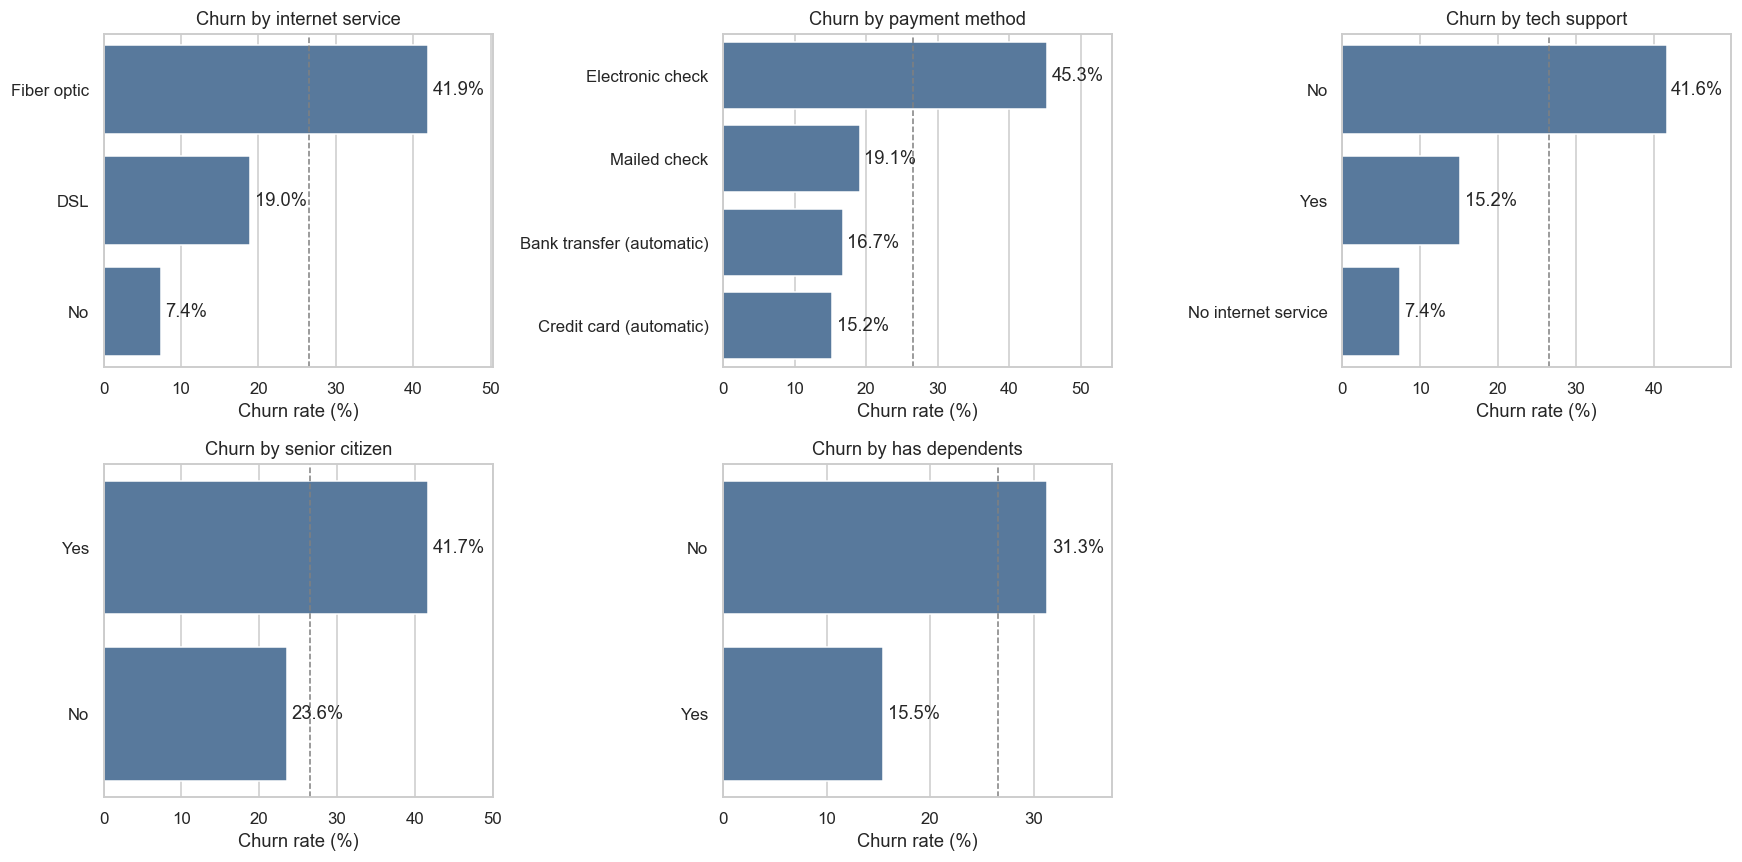

In [8]:
profile_cols = {
    "internet_service": "Internet service",
    "payment_method": "Payment method",
    "tech_support": "Tech support",
    "senior_citizen": "Senior citizen",
    "dependents": "Has dependents",
}
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()
for ax, (col, label) in zip(axes, profile_cols.items()):
    t = churn_by(col)["churn_rate"].sort_values(ascending=False)
    sns.barplot(x=t.values, y=t.index.astype(str), ax=ax, color="#4C78A8")
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
    ax.axvline(churn_rate, ls="--", color="grey", lw=1)
    ax.set_title(f"Churn by {label.lower()}")
    ax.set_xlabel("Churn rate (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, t.max() * 1.2)
axes[-1].axis("off")
plt.tight_layout()
plt.show()

## 9. Customer lifetime (survival curve)
Share of customers still active after N months of tenure, by contract type.

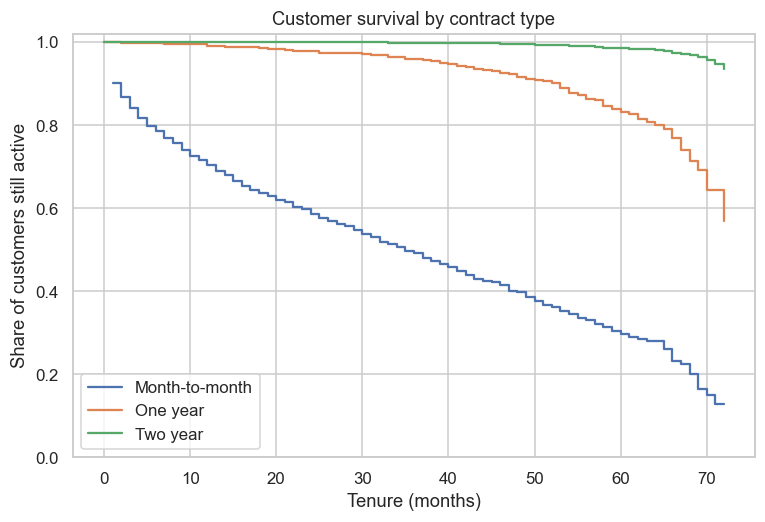

In [9]:
def km_curve(d):
    """Kaplan-Meier survival estimate from tenure (months) and churn flag."""
    t = d.groupby("tenure_months").agg(events=("churn_flag", "sum"), n=("churn_flag", "size")).sort_index()
    at_risk = len(d) - t["n"].cumsum().shift(fill_value=0)
    return (1 - t["events"] / at_risk).cumprod()

fig, ax = plt.subplots(figsize=(8, 5))
for name, g in df.groupby("contract", observed=True):
    s = km_curve(g)
    ax.step(s.index, s.values, where="post", label=name)
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Share of customers still active")
ax.set_title("Customer survival by contract type")
ax.set_ylim(0, 1.02)
ax.legend()
plt.show()

## 10. Pricing and plan
Monthly charges for churned vs retained customers, and churn by plan x contract.

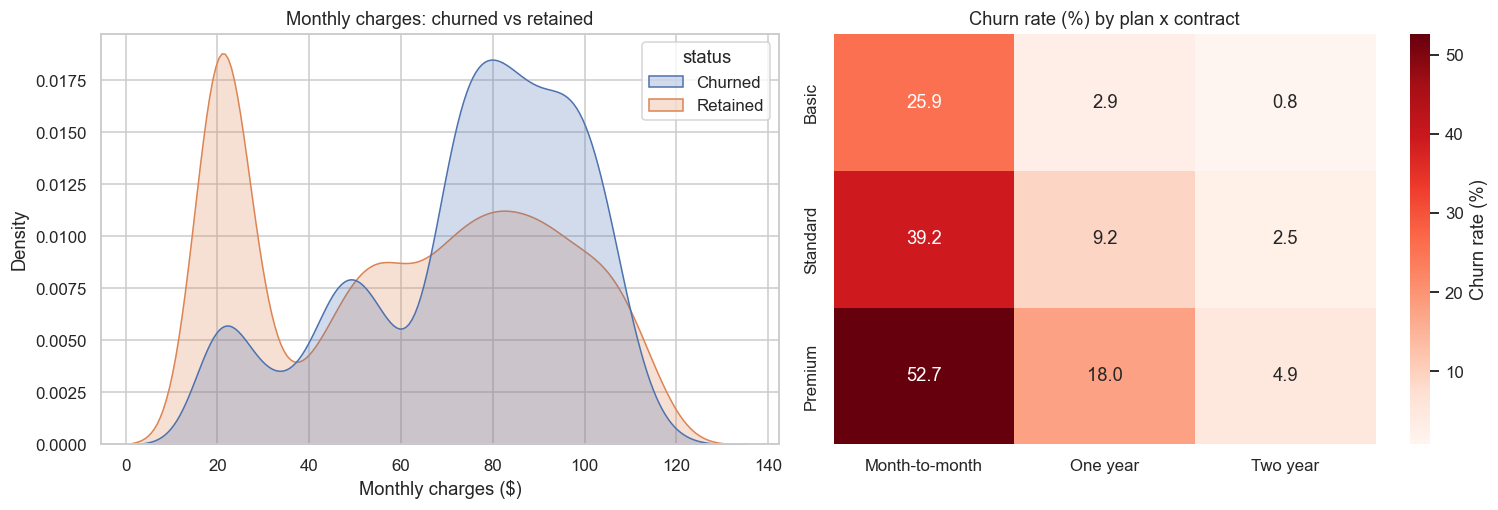

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

sns.kdeplot(data=df, x="monthly_charges", hue="status", fill=True, common_norm=False, ax=axes[0])
axes[0].set_title("Monthly charges: churned vs retained")
axes[0].set_xlabel("Monthly charges ($)")

pivot = df.pivot_table(index="plan_type", columns="contract", values="churn_flag",
                       aggfunc="mean", observed=True) * 100
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", ax=axes[1], cbar_kws={"label": "Churn rate (%)"})
axes[1].set_title("Churn rate (%) by plan x contract")
axes[1].set_xlabel("")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Careful:** `plan_type` was created by cutting `monthly_charges` into bands, so "Premium churns more" is largely the same finding as "customers paying more churn more". Say that in your write-up instead of presenting them as two separate insights.

## 11. What drives churn?
Correlation of each feature with churn, computed on the **full** data. `churn_score` and `churn_risk` are excluded because they are model outputs (including them would be circular).

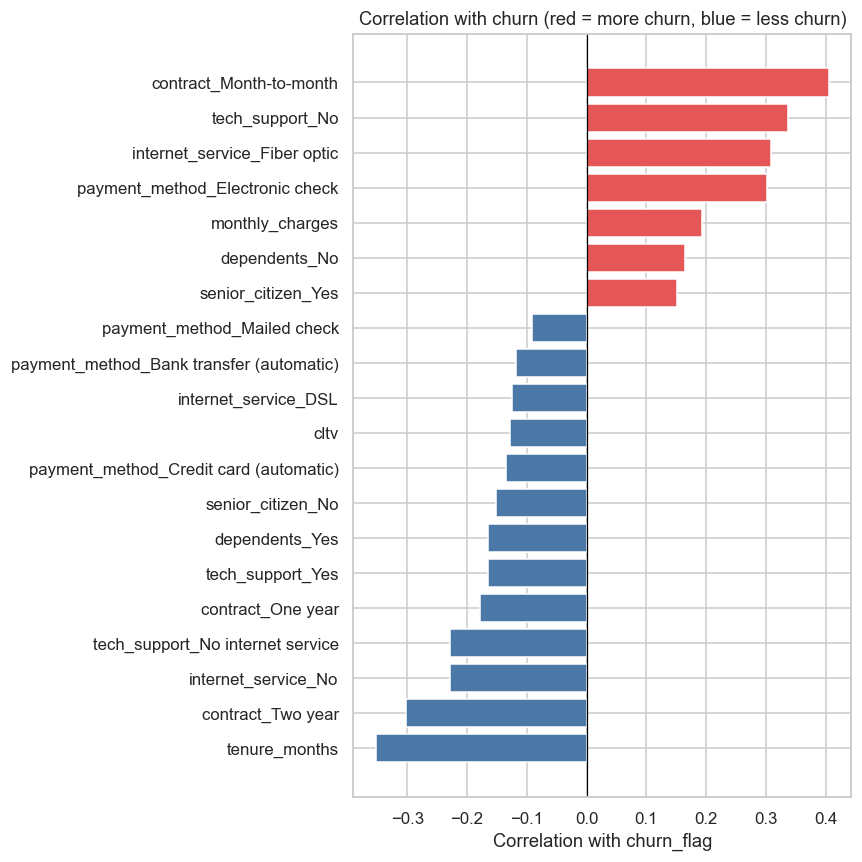

In [11]:
cat_cols = ["contract", "internet_service", "payment_method", "tech_support", "senior_citizen", "dependents"]
X = pd.get_dummies(df[cat_cols].astype(str), dtype=float)
X[["monthly_charges", "tenure_months", "cltv"]] = df[["monthly_charges", "tenure_months", "cltv"]]

corr = X.corrwith(df["churn_flag"]).sort_values()
colors = np.where(corr > 0, "#E45756", "#4C78A8")

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(corr.index, corr.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Correlation with churn (red = more churn, blue = less churn)")
ax.set_xlabel("Correlation with churn_flag")
plt.tight_layout()
plt.show()

Correlation shows association, not cause. Treat this chart as a list of segments to investigate, not as proof.

## 12. Insights and recommendations
Replace the brackets with your numbers. Each insight needs a number, a reason, and an action.

1. **[Segment] drives most churn.** [Month-to-month customers churn at X% vs Y% on longer contracts.] *Action:* [offer a discount for moving to a 1-year plan at month 3.]
2. **Churn happens early.** [X% of churned customers left within N months.] *Action:* [onboarding call and first-90-day check-in.]
3. **[Top cancellation theme] is the biggest revenue leak.** [Reason = $X MRR lost, Z% of total.] *Action:* [price match / device offer / service fix.]
4. **$[at-risk MRR] of active revenue is in the high-risk tier.** *Action:* [proactive retention list sent to the retention team each month.]

**Estimated impact:** if retention work cuts churn in the top segment by [10]%, it protects roughly $[...] of MRR a month.

## 13. Predictive Model: Which customers will churn?
Goal: rank customers by churn probability so retention can focus on the riskiest.
Leakage control: `churn_score`, `churn_risk`, `cltv`, `mrr_lost`, cancellation fields and the simulated columns are excluded.

## ML 1: Features and split

In [12]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay,
                             precision_recall_curve)

num_cols = ["tenure_months", "monthly_charges"]
cat_cols = ["contract", "internet_service", "payment_method",
            "tech_support", "senior_citizen", "dependents"]

X = df[num_cols + cat_cols].copy()
X[cat_cols] = X[cat_cols].astype(str)
y = df["churn_flag"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
print("Train:", X_train.shape, "| Test:", X_test.shape, "| Churn rate:", round(y.mean()*100, 3))

Train: (5634, 8) | Test: (1409, 8) | Churn rate: 26.537


## ML 2: Compare models

In [13]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight="balanced", random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows, fitted = [], {}
for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)])
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = pipe.predict(X_test)
    rep = classification_report(y_test, pred, output_dict=True)["1"]
    rows.append({"model": name, "cv_auc": cv_auc, "test_auc": roc_auc_score(y_test, proba),
                 "precision": rep["precision"], "recall": rep["recall"], "f1": rep["f1-score"]})
    fitted[name] = pipe
results = pd.DataFrame(rows).set_index("model").round(3)
results

,cv_auc,test_auc,precision,recall,f1
model,,,,,
Logistic Regression,0.84,0.83,0.50,0.79,0.61
Random Forest,0.83,0.84,0.54,0.73,0.62
Gradient Boosting,0.84,0.84,0.66,0.53,0.59


## ML 3: ROC curves and confusion matrix

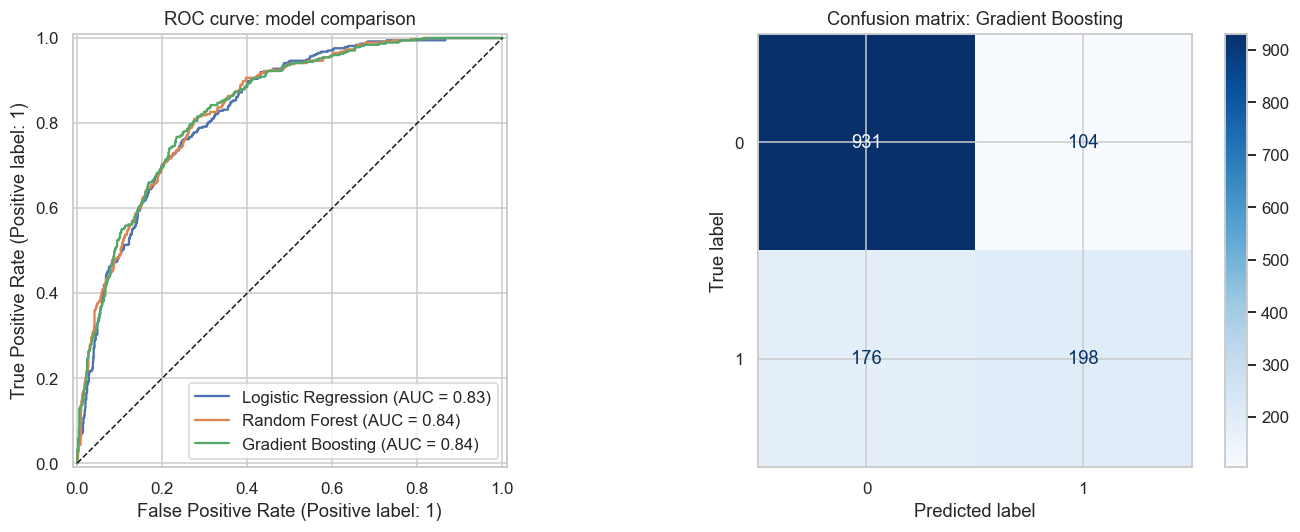

Best model: Gradient Boosting


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax[0])
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set_title("ROC curve: model comparison")

best = results["test_auc"].idxmax()
ConfusionMatrixDisplay.from_estimator(fitted[best], X_test, y_test, cmap="Blues", ax=ax[1])
ax[1].set_title(f"Confusion matrix: {best}")
plt.tight_layout(); plt.show()
print("Best model:", best)

## ML 4: What drives churn (feature importance)

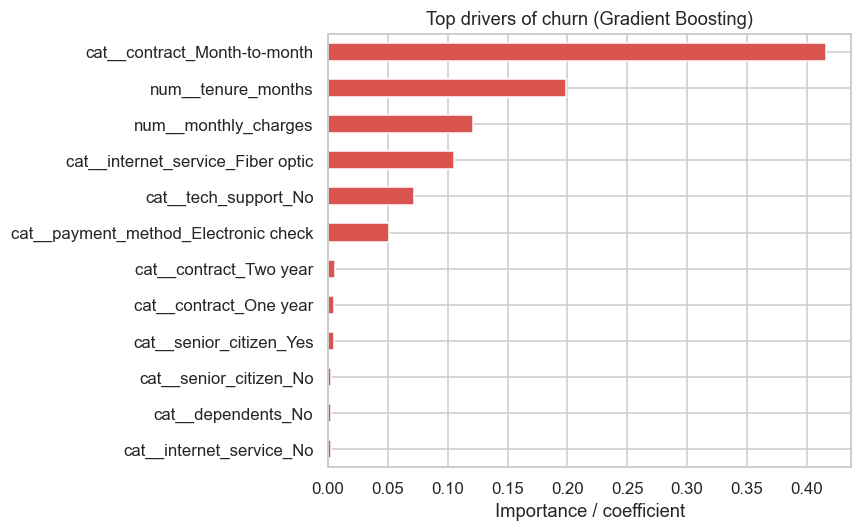

In [15]:
best_pipe = fitted[best]
names = best_pipe.named_steps["prep"].get_feature_names_out()
mdl = best_pipe.named_steps["model"]

if hasattr(mdl, "feature_importances_"):
    imp = pd.Series(mdl.feature_importances_, index=names)
else:  # logistic regression: coefficients (positive = raises churn)
    imp = pd.Series(mdl.coef_[0], index=names)

top = imp.reindex(imp.abs().sort_values(ascending=False).head(12).index).sort_values()
colors = ["#d9534f" if v > 0 else "#4a78a8" for v in top]
top.plot(kind="barh", color=colors, figsize=(8, 5))
plt.title(f"Top drivers of churn ({best})"); plt.xlabel("Importance / coefficient")
plt.tight_layout(); plt.show()

## ML 5: Pick a business threshold

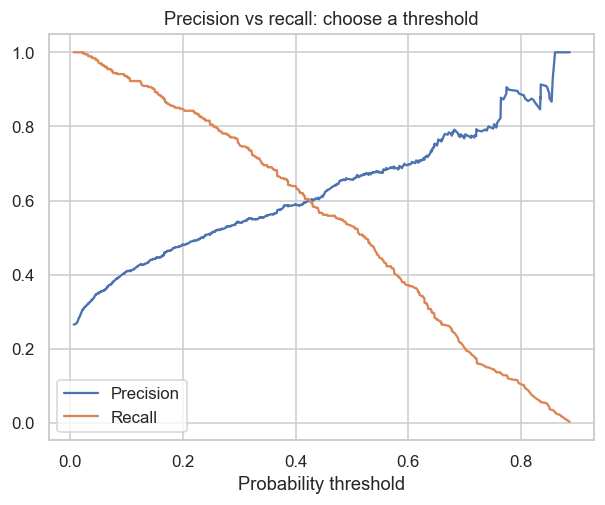

              precision    recall  f1-score   support

    Retained       0.86      0.84      0.85      1035
     Churned       0.59      0.64      0.61       374

    accuracy                           0.79      1409
   macro avg       0.73      0.74      0.73      1409
weighted avg       0.79      0.79      0.79      1409



In [27]:
proba = best_pipe.predict_proba(X_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, proba)
plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.xlabel("Probability threshold"); plt.legend()
plt.title("Precision vs recall: choose a threshold"); plt.show()

THRESH = 0.4   # lower = catch more churners, but more false alarms
pred = (proba >= THRESH).astype(int)
print(classification_report(y_test, pred, target_names=["Retained", "Churned"]))

## ML 6: Retention target list (the business output)

In [16]:
df["churn_prob"] = best_pipe.predict_proba(df[num_cols + cat_cols].astype(
    {c: str for c in cat_cols}))[:, 1]

action_list = (df[df["churn_flag"] == 0]
               .sort_values(["churn_prob", "monthly_charges"], ascending=False)
               [["customerid", "contract", "tenure_months", "monthly_charges", "churn_prob"]]
               .head(50))
display(action_list.head(10))
print("MRR covered by the top 50:", f"${action_list['monthly_charges'].sum():,.0f}")

,customerid,contract,tenure_months,monthly_charges,churn_prob
5786,1941-HOSAM,Month-to-month,1,90.10,0.86
6213,1628-BIZYP,Month-to-month,1,85.00,0.86
5906,4912-PIGUY,Month-to-month,1,84.60,0.86
3364,8775-ERLNB,Month-to-month,1,74.30,0.86
2676,7439-DKZTW,Month-to-month,1,80.55,0.85
2125,0021-IKXGC,Month-to-month,1,72.10,0.85
4551,3878-AVSOQ,Month-to-month,1,71.25,0.85
6353,9605-WGJVW,Month-to-month,1,70.20,0.85
3662,9603-OAIHC,Month-to-month,1,70.05,0.85
5657,7577-SWIFR,Month-to-month,1,89.25,0.84


MRR covered by the top 50: $4,266


### Model summary
- Best model: Gradient Boosting, AUC = 0.84	, recall on churners = 0.64, at threshold 0.4.
- Top drivers: contract type, tenure, which matches the EDA findings.
- Business use: the top 50 high-probability active customers represent $4,266 MRR to target first.
- Limitation: no hyperparameter tuning; the data is a single snapshot, so the model needs monitoring on new data.

## 14. Limitations
- Several fields (complaints, escalations, CSAT, DOB, cancellation dates, subscription type) are simulated, so no conclusions are drawn from them.
- The data is a single snapshot (30-Sep-2019), not a time series, so monthly churn trends cannot be measured.
- `plan_type` is derived from monthly charges; `churn_score` is a model output.
- Correlation is not causation.

## 15. Export for Power BI

In [30]:
df.to_csv("churn_clean.csv", index=False)
print("Saved churn_clean.csv:", df.shape)

Saved churn_clean.csv: (7043, 32)
